In [0]:

from pyspark.sql import functions as F

# Task 2B - Environment and input verification
table_name = "workspace.default.dmart_sales_clean"

df = spark.table(table_name)

print("=== DATABRICKS ENVIRONMENT ===")
print("Spark version:", spark.version)
print("Compute: Serverless CPU (verified in workspace UI)")

for setting in [
    "spark.sql.shuffle.partitions",
    "spark.sql.adaptive.enabled"
]:
    try:
        print(setting, "=", spark.conf.get(setting))
    except Exception as e:
        print(setting, "= Not exposed:", type(e).__name__)

print("\n=== INPUT DATASET ===")
print("Source table:", table_name)
print("Total records:", df.count())
print("Total columns:", len(df.columns))
print("Columns:", df.columns)

print("\n=== SCHEMA ===")
df.printSchema()

print("\n=== INPUT SAMPLE ===")
display(df.limit(5))

print("\n=== REQUIRED COLUMN CHECK ===")
required = ["ProductCategory", "Quantity", "Total"]
missing = [c for c in required if c not in df.columns]

print("Missing columns:", missing)
assert not missing, f"Required columns missing: {missing}"


=== DATABRICKS ENVIRONMENT ===
Spark version: 4.2.0
Compute: Serverless CPU (verified in workspace UI)
spark.sql.shuffle.partitions = auto
spark.sql.adaptive.enabled = Not exposed: AnalysisException

=== INPUT DATASET ===
Source table: workspace.default.dmart_sales_clean
Total records: 1000000
Total columns: 14
Columns: ['Date', 'Time', 'CustomerType', 'ProductCategory', 'UnitPrice', 'Quantity', 'Total', 'FullName', 'TransactionTimestamp', 'TransactionDate', 'Year', 'Month', 'DayOfWeek', 'Hour']

=== SCHEMA ===
root
 |-- Date: string (nullable = true)
 |-- Time: time(6) (nullable = true)
 |-- CustomerType: string (nullable = true)
 |-- ProductCategory: string (nullable = true)
 |-- UnitPrice: double (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- Total: double (nullable = true)
 |-- FullName: string (nullable = true)
 |-- TransactionTimestamp: timestamp (nullable = true)
 |-- TransactionDate: date (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Month: intege

Date,Time,CustomerType,ProductCategory,UnitPrice,Quantity,Total,FullName,TransactionTimestamp,TransactionDate,Year,Month,DayOfWeek,Hour
31-12-2023 15:41,06:04:28,Member,Grocery,10.69,4,42.76,Jai Bhatia,2023-12-31T15:41:00.000Z,2023-12-31,2023,12,1,15
07-01-2024 22:19,01:05:18,Premium,Home & Kitchen,381.03,3,1143.09,Ishaan Patel,2024-01-07T22:19:00.000Z,2024-01-07,2024,1,1,22
10-01-2024 02:09,17:31:43,Regular,Grocery,153.84,5,769.2,Tanvi Iyer,2024-01-10T02:09:00.000Z,2024-01-10,2024,1,4,2
01-06-2023 10:46,01:50:16,Regular,Electronics,341.41,4,1365.64,Zara Xavier,2023-06-01T10:46:00.000Z,2023-06-01,2023,6,5,10
23-05-2024 22:07,10:37:06,Regular,Home & Kitchen,390.16,5,1950.8,Krishna Zutshi,2024-05-23T22:07:00.000Z,2024-05-23,2024,5,5,22



=== REQUIRED COLUMN CHECK ===
Missing columns: []


In [0]:

from pyspark.sql import functions as F

# Load cleaned DMart dataset
df = spark.table("workspace.default.dmart_sales_clean")

# Validate input data
validation_df = df.agg(
    F.count("*").alias("TotalRecords"),

    F.countDistinct("ProductCategory").alias(
        "ProductCategories"
    ),

    F.sum(
        F.when(
            F.col("ProductCategory").isNull() |
            F.col("Quantity").isNull() |
            F.col("Total").isNull(),
            1
        ).otherwise(0)
    ).alias("MissingValueRows"),

    F.sum(
        F.when(F.col("Quantity") <= 0, 1)
        .otherwise(0)
    ).alias("InvalidQuantityRows"),

    F.sum(
        F.when(F.col("Total") < 0, 1)
        .otherwise(0)
    ).alias("NegativeSalesRows")
)

print("=== DMART INPUT DATA VALIDATION ===")
display(validation_df)


=== DMART INPUT DATA VALIDATION ===


TotalRecords,ProductCategories,MissingValueRows,InvalidQuantityRows,NegativeSalesRows
1000000,5,0,0,0


In [0]:
#Step 3: MapReduce Design and Implementation
df = spark.table("workspace.default.dmart_sales_clean")

# Map stage: select the fields required for aggregation
mapped_df = df.select(
    "ProductCategory",
    "Quantity",
    "Total"
)

# Reduce stage: aggregate transactions by product category
category_summary = (
    mapped_df
    .groupBy("ProductCategory")
    .agg(
        F.count("*").alias("TransactionCount"),
        F.sum("Quantity").alias("TotalQuantity"),
        F.round(F.sum("Total"), 2).alias("TotalSales")
    )
    .orderBy(F.desc("TotalSales"))
)

print("=== MAPREDUCE CATEGORY SALES RESULTS ===")
display(category_summary)

print("=== OUTPUT VALIDATION ===")
input_totals = mapped_df.agg(
    F.count("*").alias("rows"),
    F.sum("Quantity").alias("quantity"),
    F.sum("Total").alias("sales")
).first()

output_totals = category_summary.agg(
    F.sum("TransactionCount").alias("rows"),
    F.sum("TotalQuantity").alias("quantity"),
    F.sum("TotalSales").alias("sales")
).first()

print("Input rows:", input_totals["rows"])
print("Output rows represented:", output_totals["rows"])

print("Input quantity:", input_totals["quantity"])
print("Output quantity:", output_totals["quantity"])

print("Input sales:", input_totals["sales"])
print("Output sales:", output_totals["sales"])

assert input_totals["rows"] == output_totals["rows"]
assert input_totals["quantity"] == output_totals["quantity"]
assert abs(input_totals["sales"] - output_totals["sales"]) < 0.1

print("PASS: MapReduce aggregation totals verified")


=== MAPREDUCE CATEGORY SALES RESULTS ===


ProductCategory,TransactionCount,TotalQuantity,TotalSales
Beauty & Personal Care,199892,601258,1.5337800339E8
Home & Kitchen,200424,601642,1.5331603272E8
Clothing,199927,599606,1.5318490842E8
Electronics,200113,599271,1.5271964445E8
Grocery,199644,597547,1.5249603041E8


=== OUTPUT VALIDATION ===
Input rows: 1000000
Output rows represented: 1000000
Input quantity: 2999324
Output quantity: 2999324
Input sales: 765094619.3899846
Output sales: 765094619.39
PASS: MapReduce aggregation totals verified


In [0]:

# Step 4: Save and Verify MapReduce Output in Delta Lake

output_table = "workspace.default.dmart_category_summary_2b"

# Save aggregated results in Delta format
(
    category_summary.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable(output_table)
)

print("=== DELTA OUTPUT TABLE CREATED ===")
print("Table:", output_table)

# Reload persisted output
saved_df = spark.table(output_table)

print("=== SAVED OUTPUT VERIFICATION ===")
print("Saved category rows:", saved_df.count())

display(saved_df.orderBy("ProductCategory"))

# Verify Delta table metadata
print("=== TABLE METADATA ===")
display(spark.sql(f"DESCRIBE DETAIL {output_table}"))

# Confirm that persisted results match the aggregation
expected = category_summary.select(
    "ProductCategory",
    "TransactionCount",
    "TotalQuantity",
    "TotalSales"
)

actual = saved_df.select(
    "ProductCategory",
    "TransactionCount",
    "TotalQuantity",
    "TotalSales"
)

assert expected.exceptAll(actual).count() == 0
assert actual.exceptAll(expected).count() == 0

print("PASS: Saved Delta output matches MapReduce results")


=== DELTA OUTPUT TABLE CREATED ===
Table: workspace.default.dmart_category_summary_2b
=== SAVED OUTPUT VERIFICATION ===
Saved category rows: 5


ProductCategory,TransactionCount,TotalQuantity,TotalSales
Beauty & Personal Care,199892,601258,1.5337800339E8
Clothing,199927,599606,1.5318490842E8
Electronics,200113,599271,1.5271964445E8
Grocery,199644,597547,1.5249603041E8
Home & Kitchen,200424,601642,1.5331603272E8


=== TABLE METADATA ===


format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,66dd2830-fd98-49bc-96ad-69a8da11b30d,workspace.default.dmart_category_summary_2b,null,,2026-10-15T21:47:03.577Z,2026-10-15T21:47:09.000Z,List(),List(),1,1778,"Map(delta.parquet.compression.codec -> zstd, delta.parquet.format.version.afe.internal -> 2.12.0, delta.enableDeletionVectors -> true, delta.parquet.format.version -> 2.12.0, io.unitycatalog.tableId -> 4b4773e5-09a4-43f4-b0a2-2b5b2310a2a8)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


PASS: Saved Delta output matches MapReduce results


In [0]:

# Step 5: Inspect MapReduce Physical Execution Plan
from pyspark.sql import functions as F

source_df = spark.table(
    "workspace.default.dmart_sales_clean"
)

# Build the distributed aggregation query
mapreduce_plan_df = (
    source_df
    .select("ProductCategory", "Quantity", "Total")
    .groupBy("ProductCategory")
    .agg(
        F.count("*").alias("TransactionCount"),
        F.sum("Quantity").alias("TotalQuantity"),
        F.sum("Total").alias("TotalSales")
    )
)

print("=== MAPREDUCE PHYSICAL EXECUTION PLAN ===")
mapreduce_plan_df.explain(mode="formatted")

print("=== MAPREDUCE OUTPUT ===")
display(mapreduce_plan_df)


=== MAPREDUCE PHYSICAL EXECUTION PLAN ===
== Physical Plan ==
AdaptiveSparkPlan (5)
+- == Initial Plan ==
   PhotonResultStage (4)
   +- PhotonColumnarToRow (3)
      +- PhotonGroupingAgg (2)
         +- PhotonScan parquet workspace.default.dmart_sales_clean (1)


(1) PhotonScan parquet workspace.default.dmart_sales_clean
Output [3]: [ProductCategory#11605, Quantity#11607, Total#11608]
Location: PreparedDeltaFileIndex [s3://dbstorage-prod-zm7qas0dn2/uc/8bca585b-2624-4449-a326-c04ddcc0ba68/5f200a07-a276-43f4-bd45-b92f90078c9f/__unitystorage/catalogs/b9b1a287-547a-4f3e-9943-9156cbb0f8d7/tables/90dded40-0386-4542-8ea6-c5d8d166d7c7]
ReadSchema: struct<ProductCategory:string,Quantity:int,Total:double>

(2) PhotonGroupingAgg
Input [3]: [ProductCategory#11605, Quantity#11607, Total#11608]
Arguments: [ProductCategory#11605], [count(1), sum(Quantity#11607), sum(Total#11608)], [count(1)#11616L, sum(Quantity)#11619L, sum(Total)#11620], [ProductCategory#11605, count(1)#11616L AS TransactionCount#1

ProductCategory,TransactionCount,TotalQuantity,TotalSales
Grocery,199644,597547,1.524960304100026E8
Home & Kitchen,200424,601642,1.533160327199993E8
Electronics,200113,599271,1.5271964445000538E8
Clothing,199927,599606,1.53184908420004E8
Beauty & Personal Care,199892,601258,1.5337800339000195E8


In [0]:

# Step 6: Data Partitioning and Distribution Verification
from pyspark.sql import functions as F
source_df = spark.table(
    "workspace.default.dmart_sales_clean"
)

# Explicitly redistribute data into four logical partitions
partitioned_df = source_df.repartition(4)
# Inspect the distribution of records
partition_distribution = (
    partitioned_df
    .withColumn(
        "PartitionID",
        F.spark_partition_id()
    )
    .groupBy("PartitionID")
    .agg(
        F.count("*").alias("RecordCount")
    )
    .orderBy("PartitionID")
)

print("=== FOUR-PARTITION DISTRIBUTION ===")
display(partition_distribution)

# Check whether the partition distribution preserves all rows
partition_total = partition_distribution.agg(
    F.sum("RecordCount").alias("TotalRows")
).first()["TotalRows"]

source_total = source_df.count()

print("Source records:", source_total)
print("Records across partitions:", partition_total)

assert source_total == partition_total

print("PASS: All source records accounted for")


=== FOUR-PARTITION DISTRIBUTION ===


PartitionID,RecordCount
0,250000
1,250000
2,250000
3,250000


Source records: 1000000
Records across partitions: 1000000
PASS: All source records accounted for


In [0]:

# Step 7: Partition Performance Benchmarking
import time
import statistics
import pandas as pd
from pyspark.sql import functions as F

source_df = spark.table(
    "workspace.default.dmart_sales_clean"
).select("ProductCategory", "Quantity", "Total")

partition_options = [2, 4, 8, 16]
repetitions = 5

# Verify the input before benchmarking
source_count = source_df.count()
assert source_count == 1000000

benchmark_results = []

for trial in range(repetitions):
    for partitions in partition_options:

        start = time.perf_counter()

        partitioned = source_df.repartition(partitions)

        result = (
            partitioned
            .groupBy("ProductCategory")
            .agg(
                F.count("*").alias("TransactionCount"),
                F.sum("Quantity").alias("TotalQuantity"),
                F.sum("Total").alias("TotalSales")
            )
        )

        # Collect only the five aggregated output rows
        output = result.collect()

        elapsed = time.perf_counter() - start

        assert sum(
            row["TransactionCount"] for row in output
        ) == source_count

        benchmark_results.append({
            "Trial": trial + 1,
            "Partitions": partitions,
            "Seconds": elapsed
        })

        print(
            f"Trial {trial + 1}, "
            f"Partitions {partitions}: "
            f"{elapsed:.4f} seconds"
        )

benchmark_pd = pd.DataFrame(benchmark_results)

summary_pd = (
    benchmark_pd
    .groupby("Partitions")["Seconds"]
    .agg(
        MeanSeconds="mean",
        MedianSeconds="median",
        StdSeconds="std",
        MinSeconds="min",
        MaxSeconds="max"
    )
    .reset_index()
    .round(4)
)

print("=== BENCHMARK RESULTS ===")
display(benchmark_pd)

print("=== PERFORMANCE SUMMARY ===")
display(summary_pd)


Trial 1, Partitions 2: 1.0688 seconds
Trial 1, Partitions 4: 1.1430 seconds
Trial 1, Partitions 8: 1.1098 seconds
Trial 1, Partitions 16: 0.9925 seconds
Trial 2, Partitions 2: 0.9840 seconds
Trial 2, Partitions 4: 0.9853 seconds
Trial 2, Partitions 8: 0.9915 seconds
Trial 2, Partitions 16: 0.9888 seconds
Trial 3, Partitions 2: 0.9278 seconds
Trial 3, Partitions 4: 0.9466 seconds
Trial 3, Partitions 8: 0.9634 seconds
Trial 3, Partitions 16: 1.1440 seconds
Trial 4, Partitions 2: 1.0321 seconds
Trial 4, Partitions 4: 0.9278 seconds
Trial 4, Partitions 8: 0.9324 seconds
Trial 4, Partitions 16: 1.0687 seconds
Trial 5, Partitions 2: 0.9401 seconds
Trial 5, Partitions 4: 0.9607 seconds
Trial 5, Partitions 8: 0.9282 seconds
Trial 5, Partitions 16: 0.9380 seconds
=== BENCHMARK RESULTS ===


Trial,Partitions,Seconds
1,2,1.0688213590001396
1,4,1.1430323849999695
1,8,1.1098430860001827
1,16,0.9925455719999263
2,2,0.9840240160001485
2,4,0.9852558219999992
2,8,0.9914827600000535
2,16,0.9888321160001396
3,2,0.9278423380001186
3,4,0.9466328030002842


=== PERFORMANCE SUMMARY ===


Partitions,MeanSeconds,MedianSeconds,StdSeconds,MinSeconds,MaxSeconds
2,0.9906,0.984,0.0599,0.9278,1.0688
4,0.9927,0.9607,0.0866,0.9278,1.143
8,0.9851,0.9634,0.0743,0.9282,1.1098
16,1.0264,0.9925,0.0806,0.938,1.144


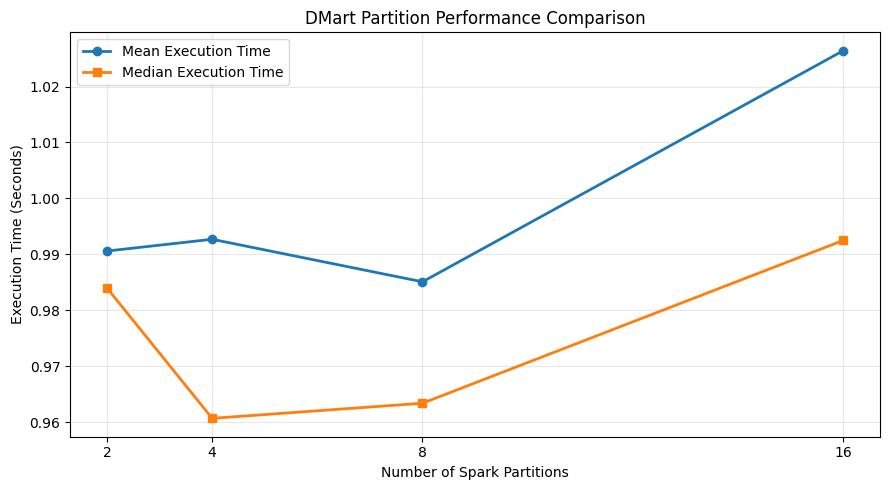

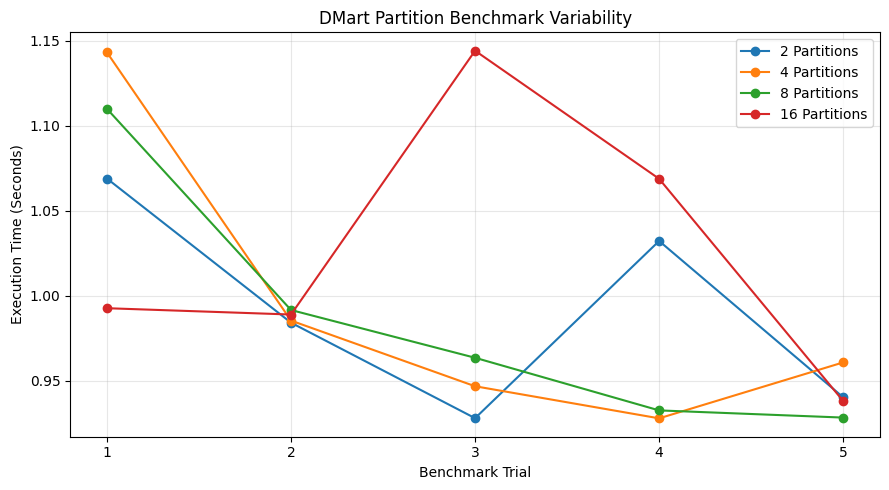

In [0]:

# Step 8: Visualise Partition Benchmark Results
import matplotlib.pyplot as plt
# Graph 1: Mean and median execution times
plt.figure(figsize=(9, 5))

plt.plot(
    summary_pd["Partitions"],
    summary_pd["MeanSeconds"],
    marker="o",
    linewidth=2,
    label="Mean Execution Time"
)

plt.plot(
    summary_pd["Partitions"],
    summary_pd["MedianSeconds"],
    marker="s",
    linewidth=2,
    label="Median Execution Time"
)

plt.title("DMart Partition Performance Comparison")
plt.xlabel("Number of Spark Partitions")
plt.ylabel("Execution Time (Seconds)")
plt.xticks([2, 4, 8, 16])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2: Run-to-run variation
plt.figure(figsize=(9, 5))

for partitions in [2, 4, 8, 16]:
    subset = benchmark_pd[
        benchmark_pd["Partitions"] == partitions
    ]

    plt.plot(
        subset["Trial"],
        subset["Seconds"],
        marker="o",
        label=f"{partitions} Partitions"
    )

plt.title("DMart Partition Benchmark Variability")
plt.xlabel("Benchmark Trial")
plt.ylabel("Execution Time (Seconds)")
plt.xticks([1, 2, 3, 4, 5])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [0]:

# Step 9: Serverless-Compatible MapReduce Scalability Benchmark

import time
import pandas as pd
from pyspark.sql import functions as F
from pyspark.sql.window import Window

source_df = spark.table(
    "workspace.default.dmart_sales_clean"
).select("ProductCategory", "Quantity", "Total")

dataset_sizes = [100000, 500000, 1000000]
fixed_partitions = 4
repetitions = 5

# Prepare a deterministic ordering using a stable hash.
# Ties can exist, but the same source table is used for the experiment.
ordered_df = source_df.withColumn(
    "SortKey",
    F.xxhash64("ProductCategory", "Quantity", "Total")
)

scalability_results = []

for size in dataset_sizes:

    subset_table = f"workspace.default.dmart_scale_{size}_2b"

    # Prepare input outside the timed experiment
    subset_df = (
        ordered_df
        .orderBy("SortKey", "ProductCategory", "Quantity", "Total")
        .limit(size)
        .drop("SortKey")
    )

    (
        subset_df.write
        .format("delta")
        .mode("overwrite")
        .saveAsTable(subset_table)
    )

    test_df = spark.table(subset_table)
    actual_size = test_df.count()

    assert actual_size == size

    print(f"\n=== TESTING {actual_size:,} RECORDS ===")

    for trial in range(1, repetitions + 1):

        start = time.perf_counter()

        result = (
            test_df
            .repartition(fixed_partitions)
            .groupBy("ProductCategory")
            .agg(
                F.count("*").alias("TransactionCount"),
                F.sum("Quantity").alias("TotalQuantity"),
                F.sum("Total").alias("TotalSales")
            )
        )

        output = result.collect()

        elapsed = time.perf_counter() - start

        assert sum(
            row["TransactionCount"] for row in output
        ) == actual_size

        scalability_results.append({
            "Rows": actual_size,
            "Trial": trial,
            "Partitions": fixed_partitions,
            "Seconds": elapsed
        })

        print(
            f"Rows={actual_size}, "
            f"Trial={trial}, "
            f"Time={elapsed:.4f} seconds"
        )

scalability_pd = pd.DataFrame(scalability_results)

scalability_summary = (
    scalability_pd
    .groupby("Rows")["Seconds"]
    .agg(
        MeanSeconds="mean",
        MedianSeconds="median",
        StdSeconds="std",
        MinSeconds="min",
        MaxSeconds="max"
    )
    .reset_index()
    .round(4)
)

print("=== SCALABILITY BENCHMARK RESULTS ===")
display(scalability_pd)

print("=== SCALABILITY SUMMARY ===")
display(scalability_summary)



=== TESTING 100,000 RECORDS ===
Rows=100000, Trial=1, Time=2.0937 seconds
Rows=100000, Trial=2, Time=1.3406 seconds
Rows=100000, Trial=3, Time=1.2567 seconds
Rows=100000, Trial=4, Time=1.4839 seconds
Rows=100000, Trial=5, Time=1.4107 seconds

=== TESTING 500,000 RECORDS ===
Rows=500000, Trial=1, Time=1.3463 seconds
Rows=500000, Trial=2, Time=0.9930 seconds
Rows=500000, Trial=3, Time=1.0608 seconds
Rows=500000, Trial=4, Time=1.0325 seconds
Rows=500000, Trial=5, Time=1.1390 seconds

=== TESTING 1,000,000 RECORDS ===
Rows=1000000, Trial=1, Time=1.3864 seconds
Rows=1000000, Trial=2, Time=0.9642 seconds
Rows=1000000, Trial=3, Time=1.0312 seconds
Rows=1000000, Trial=4, Time=0.9881 seconds
Rows=1000000, Trial=5, Time=1.2078 seconds
=== SCALABILITY BENCHMARK RESULTS ===


Rows,Trial,Partitions,Seconds
100000,1,4,2.093682631999968
100000,2,4,1.3406192570000144
100000,3,4,1.2566890929999772
100000,4,4,1.4839208939999935
100000,5,4,1.410704644999953
500000,1,4,1.346328380999978
500000,2,4,0.9930148719999465
500000,3,4,1.0608085819999928
500000,4,4,1.0325349750000328
500000,5,4,1.1390105429999835


=== SCALABILITY SUMMARY ===


Rows,MeanSeconds,MedianSeconds,StdSeconds,MinSeconds,MaxSeconds
100000,1.5171,1.4107,0.3331,1.2567,2.0937
500000,1.1143,1.0608,0.1403,0.993,1.3463
1000000,1.1155,1.0312,0.179,0.9642,1.3864


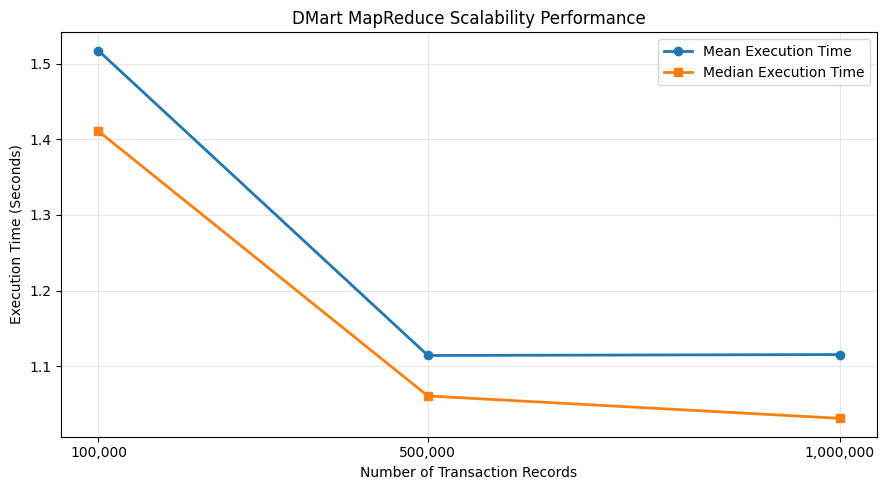

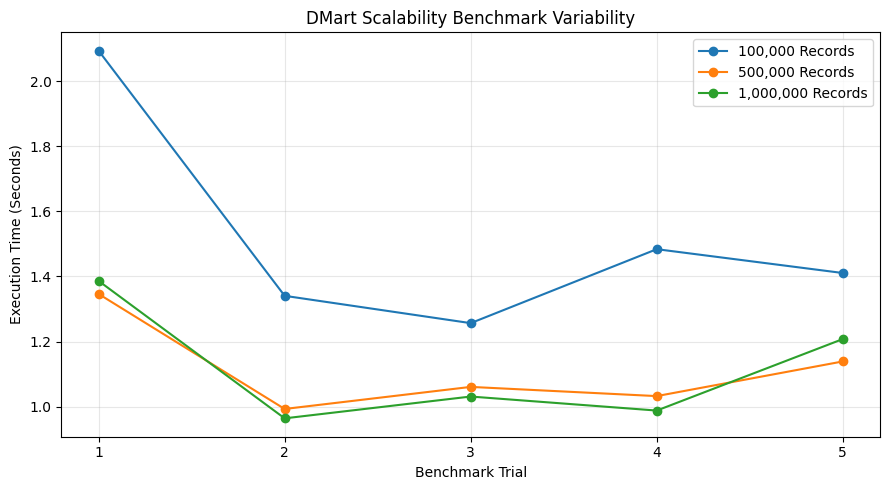

In [0]:

# Step 10: Visualise MapReduce Scalability Results

import matplotlib.pyplot as plt

# Graph 1: Mean and median times by dataset size
plt.figure(figsize=(9, 5))

plt.plot(
    scalability_summary["Rows"],
    scalability_summary["MeanSeconds"],
    marker="o",
    linewidth=2,
    label="Mean Execution Time"
)

plt.plot(
    scalability_summary["Rows"],
    scalability_summary["MedianSeconds"],
    marker="s",
    linewidth=2,
    label="Median Execution Time"
)

plt.title("DMart MapReduce Scalability Performance")
plt.xlabel("Number of Transaction Records")
plt.ylabel("Execution Time (Seconds)")
plt.xticks([100000, 500000, 1000000],
           ["100,000", "500,000", "1,000,000"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2: Variability across five trials
plt.figure(figsize=(9, 5))

for size in [100000, 500000, 1000000]:
    subset = scalability_pd[
        scalability_pd["Rows"] == size
    ]

    plt.plot(
        subset["Trial"],
        subset["Seconds"],
        marker="o",
        label=f"{size:,} Records"
    )

plt.title("DMart Scalability Benchmark Variability")
plt.xlabel("Benchmark Trial")
plt.ylabel("Execution Time (Seconds)")
plt.xticks([1, 2, 3, 4, 5])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [0]:

# Step 11: Serverless Compute Configuration Evidence

print("=== COMPUTE ENVIRONMENT ===")
print("Spark version:", spark.version)

settings = [
    "spark.sql.shuffle.partitions",
    "spark.sql.adaptive.enabled",
    "spark.databricks.photon.enabled",
    "spark.sql.autoBroadcastJoinThreshold"
]

for setting in settings:
    try:
        print(setting, "=", spark.conf.get(setting))
    except Exception as e:
        print(
            setting,
            "= Not exposed:",
            type(e).__name__
        )

print("\n=== SOURCE TABLE METADATA ===")
display(
    spark.sql(
        "DESCRIBE DETAIL workspace.default.dmart_sales_clean"
    )
)

print("\n=== COMPUTE INFORMATION ===")
print("Compute type: Serverless CPU")
print("Environment: Databricks Free Edition")
print("Photon: Observed in Step 5 execution plan")
print("Worker count: Managed by Databricks Serverless")


=== COMPUTE ENVIRONMENT ===
Spark version: 4.2.0
spark.sql.shuffle.partitions = auto
spark.sql.adaptive.enabled = Not exposed: AnalysisException
spark.databricks.photon.enabled = Not exposed: AnalysisException
spark.sql.autoBroadcastJoinThreshold = Not exposed: AnalysisException

=== SOURCE TABLE METADATA ===


format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,ad23ca8f-9045-4ca7-99ca-3f49cbf87d33,workspace.default.dmart_sales_clean,null,,2026-10-14T04:05:58.945Z,2026-10-14T19:57:28.000Z,List(),List(),1,27457996,"Map(delta.parquet.compression.codec -> zstd, delta.parquet.format.version.afe.internal -> 2.12.0, delta.enableDeletionVectors -> true, delta.parquet.format.version -> 2.12.0, io.unitycatalog.tableId -> 90dded40-0386-4542-8ea6-c5d8d166d7c7)",3,7,"List(appendOnly, deletionVectors, invariants, timeType-preview)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false



=== COMPUTE INFORMATION ===
Compute type: Serverless CPU
Environment: Databricks Free Edition
Photon: Observed in Step 5 execution plan
Worker count: Managed by Databricks Serverless


In [0]:

# Step 12: Restore and Verify Task 2B Benchmark Evidence

import pandas as pd

# Restore actual partition benchmark timings from Step 7
partition_times = {
    2: [1.0688, 0.9840, 0.9278, 1.0321, 0.9401],
    4: [1.1430, 0.9853, 0.9466, 0.9278, 0.9607],
    8: [1.1098, 0.9915, 0.9634, 0.9324, 0.9282],
    16: [0.9925, 0.9888, 1.1440, 1.0687, 0.9380]
}

benchmark_results = []

for partitions, times in partition_times.items():
    for trial, seconds in enumerate(times, start=1):
        benchmark_results.append({
            "Trial": trial,
            "Partitions": partitions,
            "Seconds": seconds
        })

benchmark_pd = pd.DataFrame(benchmark_results)

summary_pd = (
    benchmark_pd.groupby("Partitions")["Seconds"]
    .agg(
        MeanSeconds="mean",
        MedianSeconds="median",
        StdSeconds="std",
        MinSeconds="min",
        MaxSeconds="max"
    )
    .reset_index()
    .round(4)
)

# Restore actual scalability timings from Step 9
scalability_times = {
    100000: [2.0937, 1.3406, 1.2567, 1.4839, 1.4107],
    500000: [1.3463, 0.9930, 1.0608, 1.0325, 1.1390],
    1000000: [1.3864, 0.9642, 1.0312, 0.9881, 1.2078]
}

scalability_results = []

for rows, times in scalability_times.items():
    for trial, seconds in enumerate(times, start=1):
        scalability_results.append({
            "Rows": rows,
            "Trial": trial,
            "Partitions": 4,
            "Seconds": seconds
        })

scalability_pd = pd.DataFrame(scalability_results)

scalability_summary = (
    scalability_pd.groupby("Rows")["Seconds"]
    .agg(
        MeanSeconds="mean",
        MedianSeconds="median",
        StdSeconds="std",
        MinSeconds="min",
        MaxSeconds="max"
    )
    .reset_index()
    .round(4)
)

print("=== PARTITION BENCHMARK SUMMARY ===")
display(summary_pd)

print("=== SCALABILITY BENCHMARK SUMMARY ===")
display(scalability_summary)

best_partition = summary_pd.loc[
    summary_pd["MeanSeconds"].idxmin()
]

print("\n=== OBSERVED BEST PARTITION ===")
print("Partitions:", int(best_partition["Partitions"]))
print("Mean seconds:", best_partition["MeanSeconds"])

assert len(benchmark_pd) == 20
assert len(scalability_pd) == 15

print("\nTotal benchmark observations:",
      len(benchmark_pd) + len(scalability_pd))

print("PASS: Benchmark summaries reconstructed")


=== PARTITION BENCHMARK SUMMARY ===


Partitions,MeanSeconds,MedianSeconds,StdSeconds,MinSeconds,MaxSeconds
2,0.9906,0.984,0.0599,0.9278,1.0688
4,0.9927,0.9607,0.0866,0.9278,1.143
8,0.9851,0.9634,0.0743,0.9282,1.1098
16,1.0264,0.9925,0.0806,0.938,1.144


=== SCALABILITY BENCHMARK SUMMARY ===


Rows,MeanSeconds,MedianSeconds,StdSeconds,MinSeconds,MaxSeconds
100000,1.5171,1.4107,0.3331,1.2567,2.0937
500000,1.1143,1.0608,0.1403,0.993,1.3463
1000000,1.1155,1.0312,0.179,0.9642,1.3864



=== OBSERVED BEST PARTITION ===
Partitions: 8
Mean seconds: 0.9851

Total benchmark observations: 35
PASS: Benchmark summaries reconstructed
